# Notebook 3: Central learning versus independent learning

#### **The task**
Same as notebook 2: the pen is in the middle, the task never ends, and the dogs get +1 for every step the sheep is in the pen (-0.1 when it is outside). Every 300 steps a new sheep arrives. We use the **calm sheep** (`sheep_panic = 0`): in notebook 2 we saw that two dogs keep a calm sheep in the pen much better than one dog. Both dogs learn with SARSA.

#### **Two ways to organize the learning**
In multi-agent reinforcement learning there are two basic ways to deal with more than one agent:

**Central learning.** There is one learner (one Q-table) that controls both dogs. Its actions are *joint actions*: a move for dog 1 **and** a move for dog 2 at the same time. With 5 moves per dog that is 5 x 5 = 25 joint actions. Its Q-function looks like this:

\begin{equation}
Q(s, a_1, a_2)
\end{equation}

"How good is it if, in state s, dog 1 does $a_1$ **and** dog 2 does $a_2$?" Because it picks the pair, the dogs are coordinated by construction. But it has to learn the value of every combination.

**Independent learning.** Every dog has its own learner with its own Q-table, and only its own 5 actions:

\begin{equation}
Q_1(s, a_1) \quad \text{and} \quad Q_2(s, a_2)
\end{equation}

"How good is it if, in state s, *I* do $a_1$?" The other dog is part of the environment. So $Q_1(s, a_1)$ is really an average over what the other dog tends to do. When the other dog changes its habits (because it is learning too), the same entry should get a different value. This is the **non-stationarity** problem of multi-agent learning. In the literature this is called *independent Q-learning*; here we do the same thing with SARSA.

#### **Bodies and governors**
To make this clear in the code, we separate **bodies** from **governors**:
* a `Dog` is just a body on the field (a position, nothing more)
* a `Learner` is a governor: a Q-table plus SARSA, and it controls one or more dogs

Central learning = 1 governor controlling 2 bodies. Independent learning = 2 governors, each controlling 1 body.

#### **What does a learner see?**
To make it a fair comparison, **both set-ups see exactly the same state**: the position of the sheep (x, y), and for each dog roughly where the sheep is relative to that dog (left / same / right, and below / same / above). So the only difference between the two set-ups is the Q-function: joint actions, or own actions.

Note: this view is coarser than in notebook 2 (there each dog saw the sheep up to 3 cells away in detail). We need a coarse view here, otherwise the central learner's table gets too big to learn in reasonable time. So the dogs do a bit worse than in notebook 2.

So remember we have the following components:
* Learning: central or independent
* Whether the sheep panics
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* Number of training steps

# Lets get started

In [1]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import copy

# the five things a dog can do: stay, right, left, up, down (as steps in x and y)
ACTIONS = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]
from mesa.agent import AgentSet   # a group of agents (we use it for the learners)
import itertools                  # to make all combinations of moves (joint actions)

# Agent setup: the sheep (rule-based, same as notebook 1 and 2)

In [2]:
class Sheep(CellAgent):
    """A rule-based sheep that flees from dogs.
    flee_radius: how close a dog must be before the sheep reacts
    sheep_panic: chance that a fleeing sheep panics and sprints 2 cells away instead of 1
                 (0 = calm sheep, higher = panics more easily)

    The sheep does not learn. It follows the same simple rules every step:
      1. a dog is close  -> flee (and sometimes panic and sprint)
      2. no dog is close -> mostly graze (stay put), sometimes wander a bit
    It is a CellAgent: it lives on a cell of the grid, and moves by switching to another cell.
    """
    def __init__(self, model, cell, flee_radius=2, sheep_panic=0.0):
        super().__init__(model)
        self.cell = cell                  # the cell the sheep starts on
        self.flee_radius = flee_radius
        self.sheep_panic = sheep_panic

    def distance_to_nearest_dog(self, position):
        """Distance (in steps, diagonal counts as one step) from a position to the nearest dog.

        We measure the distance as the largest of the x-distance and the y-distance
        (this is called the Chebyshev distance). So a dog 2 cells to the right and 1 cell up
        is at distance 2: it is within reach in 2 diagonal-ish steps.
        """
        # the positions of all dogs, as (x, y) coordinates
        dog_positions = [dog.cell.coordinate for dog in self.model.dogs]
        # for every dog: the distance to the position. Then take the smallest: the nearest dog
        return min(max(abs(position[0] - dx), abs(position[1] - dy)) for dx, dy in dog_positions)

    def step(self):
        x, y = self.cell.coordinate
        # where could the sheep go? (stay, or one step in four directions, but not off the field)
        # ACTIONS are the same five moves the dogs have: stay, right, left, up, down
        options = [(x + ax, y + ay) for ax, ay in ACTIONS if self.model.inside((x + ax, y + ay))]

        if self.distance_to_nearest_dog((x, y)) <= self.flee_radius:
            # a dog is close: flee.
            # for every option, how far would we be from the nearest dog? Find the biggest distance...
            best = max(self.distance_to_nearest_dog(p) for p in options)
            # ...and pick one of the options with that distance (at random, if there are several)
            target = self.model.random.choice([p for p in options if self.distance_to_nearest_dog(p) == best])
            # panic: sometimes the sheep sprints one cell further in the same direction.
            # (target - current position) is the step the sheep takes; adding it twice gives a 2-cell sprint
            if self.model.random.random() < self.sheep_panic:
                # 50% percent it sprints, 50% it just flees randomly.
                if self.model.random.random() < 0.5:
                    jump = (2 * target[0] - x, 2 * target[1] - y) # the cell 2 steps away in the same direction
                else:
                    jump = self.model.random.choice(options)      # just flee randomly
                if self.model.inside(jump):                   # only if the sprint stays on the field
                    target = jump
        elif self.model.random.random() > 0.2:
            target = (x, y)                                   # no dog close: mostly graze (stay put, 80% of the time)
        else:
            target = self.model.random.choice(options)        # and sometimes wander a bit (20% of the time)

        # move the sheep to its new cell
        self.cell = self.model.grid[target]

# Agent setup: the dog (just a body)
A dog has a position and can do a move it is told to do. It does not decide anything itself.

In [3]:
class Dog(CellAgent):
    """A dog body: it only has a position. A Learner (a governor) tells it which move to make."""
    def __init__(self, model, cell):
        super().__init__(model)
        self.cell = cell                  # the cell the dog starts on

    def do_move(self, move):
        """Do one of the five moves (an index into ACTIONS), if it stays on the field."""
        x, y = self.cell.coordinate
        new_position = (x + ACTIONS[move][0], y + ACTIONS[move][1])
        if self.model.inside(new_position):        # dogs cannot leave the field
            self.cell = self.model.grid[new_position]

# Agent setup: the learner (a governor, with SARSA)
A learner controls a list of dogs. The actions of the learner are all combinations of moves for the dog or dogs (if it controls both):
* controlling 1 dog: 5 actions, e.g. `(right,)`
* controlling 2 dogs: 5 x 5 = 25 joint actions, e.g. `(right, stay)`

The SARSA part (`choose`, `learn`) is exactly the same as in notebook 2. The learner does not care whether an action is a single move or a joint move: it is just an entry in the table.

In [4]:
class Learner(mesa.Agent):
    """A SARSA learner (a governor) that controls one or more dogs (bodies).
    dogs: the dog bodies this learner controls (one dog = independent learning, two dogs = central learning)
    alpha: learning rate (how far we move a Q-value when we learn something new)
    gamma: discount (how much we care about rewards further in the future)
    epsilon: exploration (how often we pick a random action instead of the best one)
    """
    def __init__(self, model, dogs, alpha=0.1, gamma=0.95, epsilon=0.1):
        super().__init__(model)
        self.dogs = dogs

        # The list of actions. Each entry is ONE action in the RL sense: the learner picks exactly one per step.
        # With one dog, an action is one move: 5 actions, e.g. (1,) = "my dog goes right".
        # With two dogs (repeat=2), an action is a move for dog 1 AND a move for dog 2,
        # together counted as ONE action: 5 x 5 = 25 actions, e.g. (1, 0) = "dog 1 right, dog 2 stays".
        self.actions = list(itertools.product(range(len(ACTIONS)), repeat=len(dogs)))

        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True    # we can switch learning off (e.g., to freeze a trained learner)

        # The Q-table: a dictionary from state to an array with one value per (joint) action.
        # Central learner: 25 values per state. Independent learner: 5 values per state.
        self.Q = {}

        # SARSA needs to know the state s it was in AND the action a it chose there.
        self.state = None       # the state s we were in when we chose our action
        self.action = None      # the action a we chose in s (an index into self.actions)

    def q_values(self, state):
        """Look up the Q values of a state. A state we have never seen starts at 0 for every action."""
        if state not in self.Q:
            self.Q[state] = np.zeros(len(self.actions))
        return self.Q[state]

    def choose(self, state):
        """Epsilon-greedy over our (joint) actions.
        Note: a central learner explores with JOINT random actions (both dogs random at once)."""
        if self.model.random.random() < self.epsilon:
            return self.model.random.randrange(len(self.actions))   # explore: random action
        q = self.q_values(state)                                    # exploit: best action so far
        return self.model.random.choice(np.flatnonzero(q == q.max()).tolist())   # random among ties

    def move(self):
        """Tell each of our dogs which move to make."""
        if self.state is None:                   # very first step: observe and choose now
            self.state = self.model.observe()
            self.action = self.choose(self.state)
        # unpack our action: one move for every dog we control
        for dog, move in zip(self.dogs, self.actions[self.action]):
            dog.do_move(move)

    def learn(self, reward):
        """The SARSA update: S, A, R, S', A' (same as notebook 2).
        self.state and self.action are the snapshot from BEFORE the move (s and a);
        next_state and next_action are from AFTER the move (s' and a')."""
        next_state = self.model.observe()        # S': everybody sees the same state (computed by the model)
        next_action = self.choose(next_state)    # A': what we will really do next
        if self.learning:
            q = self.q_values(self.state)        # the Q-values of s (BEFORE the move)
            # TD error: reward + discounted value of what we will do next - what we expected
            td_error = reward + self.gamma * self.q_values(next_state)[next_action] - q[self.action]
            q[self.action] += self.alpha * td_error
        self.state, self.action = next_state, next_action   # slide one step forward

    def table_size(self):
        """How many numbers are in our Q-table (states seen x actions)?"""
        return len(self.Q) * len(self.actions)

# Model setup
The model creates two dog bodies, and then either one learner for both dogs (central) or one learner per dog (independent). The state is computed by the model (`observe()`), so all learners see exactly the same thing.

In [5]:
class HerdingModel(mesa.Model):
    """The herding model with the pen in the middle, two dogs, and central or independent learning.

    learning: "central" (one learner for both dogs) or "independent" (one learner per dog)
    sheep_panic: chance that the fleeing sheep panics (0 = calm sheep)
    size: the field is size x size cells
    new_sheep_every: every so many steps a new sheep arrives at a random place (this is NOT an episode end)
    flee_radius: how close a dog must be before the sheep reacts
    alpha, gamma, epsilon: the learning parameters, passed on to every learner
    """
    def __init__(self, learning="independent", sheep_panic=0.0, size=8, new_sheep_every=300,
                 flee_radius=2, alpha=0.1, gamma=0.95, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.learning_setup = learning
        self.size = size
        self.new_sheep_every = new_sheep_every
        # the field: a grid of size x size cells. torus=False means the edges are walls
        self.grid = OrthogonalMooreGrid((size, size), torus=False, random=self.random)
        # the pen is the 2 x 2 square in the middle of the field. pen_low is its lower-left corner
        self.pen_low = size // 2 - 1

        # bodies: one sheep, two dogs
        self.sheep = Sheep(self, self.random_cell(), flee_radius=flee_radius, sheep_panic=sheep_panic)
        self.dogs = Dog.create_agents(self, 2, [self.random_cell() for _ in range(2)])
        dog_list = list(self.dogs)

        # governors: central = one learner for both dogs, independent = one learner per dog
        if learning == "central":
            governors = [Learner(self, dog_list, alpha=alpha, gamma=gamma, epsilon=epsilon)]
        elif learning == "independent":
            governors = [Learner(self, [dog], alpha=alpha, gamma=gamma, epsilon=epsilon) for dog in dog_list]
        self.learners = AgentSet(governors, random=self.random)   # a group of learners we can tell to do something together

        # bookkeeping
        self.t = 0                                   # total number of steps (there are no episodes)
        self.recent_in_pen = deque(maxlen=10_000)    # was the sheep in the pen? (last 10,000 steps)
        self.in_pen_share = 0                        # share of the last 10,000 steps the sheep was in the pen
        self.block = []                              # in-pen values of the current block of 5,000 steps
        self.block_log = []                          # one row per block of 5,000 steps, for the learning curves

        # Data collection!
        # The datacollector runs every step (the batch runner of our Mesa version needs that).
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "in_pen_share": "in_pen_share",
                # the total number of Q-values of all learners together (how much there is to learn)
                "q_table_size": lambda m: sum(l.table_size() for l in m.learners),
            }
        )

    def observe(self):
        """The state: the sheep position + a coarse direction from each dog to the sheep.

        e.g. (5, 2, 1, -1, -1, 0) means: the sheep is at x=5, y=2;
        for dog 1 the sheep is to the right and below; for dog 2 the sheep is to the left, at the same height.
        """
        sx, sy = self.sheep.cell.coordinate
        state = [sx, sy]
        for dog in self.dogs:
            x, y = dog.cell.coordinate
            # np.sign gives -1, 0 or +1: left/same/right, and below/same/above
            state += [int(np.sign(sx - x)), int(np.sign(sy - y))]
        return tuple(state)

    def inside(self, position):
        """Is this position on the field? (used by the dogs and the sheep, so nobody walks off)"""
        return 0 <= position[0] < self.size and 0 <= position[1] < self.size

    def in_pen(self, position):
        """Is this position in the pen (the 2 x 2 square in the middle)?"""
        return (self.pen_low <= position[0] <= self.pen_low + 1) and (self.pen_low <= position[1] <= self.pen_low + 1)

    def random_cell(self):
        """A random cell that is not in the pen."""
        while True:
            position = (self.random.randrange(self.size), self.random.randrange(self.size))
            if not self.in_pen(position):
                return self.grid[position]

    def step(self):
        """One model step: the learners move their dogs, the sheep reacts, reward, and the learners learn."""
        self.learners.do("move")      # every learner moves the dog(s) it controls
        self.sheep.step()             # the sheep reacts
        self.t += 1

        sheep_in = self.in_pen(self.sheep.cell.coordinate)
        reward = 1.0 if sheep_in else -0.1        # shared reward

        # bookkeeping for the measures
        self.recent_in_pen.append(sheep_in)
        self.block.append(sheep_in)
        if len(self.block) == 5_000:              # every 5,000 steps: one point for the learning curve
            self.block_log.append({"step": self.t, "in_pen_share": np.mean(self.block)})
            self.block = []
            self.in_pen_share = np.mean(self.recent_in_pen)

        if self.t % self.new_sheep_every == 0:     # a new sheep arrives (not the end of an episode)
            self.sheep.cell = self.random_cell()

        self.learners.do("learn", reward)  # every learner does its SARSA update
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train
Central and independent learning, 1,500,000 steps each. This takes several minutes.

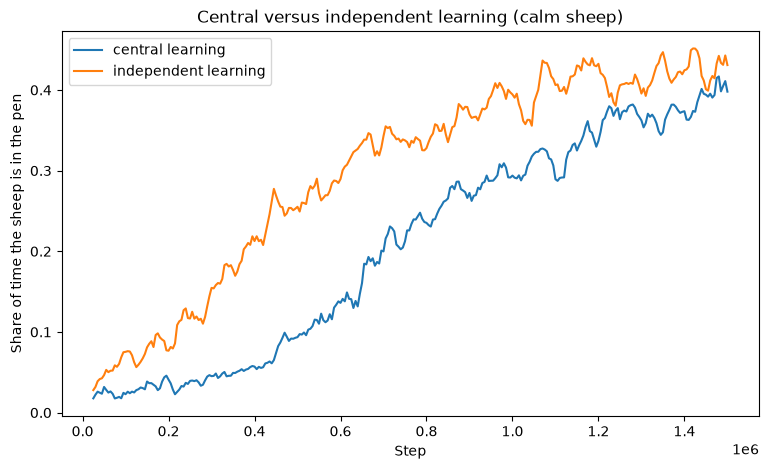

In [6]:
def train(n_steps=1_500_000, **params):
    """Make a model and run it for n_steps steps. Returns the trained model."""
    model = HerdingModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

trained = {setup: train(learning=setup, rng=1) for setup in ["central", "independent"]}

# plot the learning curves: share of time in the pen per block of 5,000 steps (rolling mean of 5 blocks)
fig, ax = plt.subplots(figsize=(9, 5))
for setup, model in trained.items():
    df = pd.DataFrame(model.block_log)
    ax.plot(df["step"], df["in_pen_share"].rolling(5).mean(), label=setup + " learning")
ax.set_xlabel("Step")
ax.set_ylabel("Share of time the sheep is in the pen")
ax.set_title("Central versus independent learning (calm sheep)")
ax.legend()
plt.show()

# How big are the Q-tables?
The central learner has 25 actions per state, each independent learner only 5. How many numbers did each set-up have to learn?

In [7]:
for setup, model in trained.items():
    for i, learner in enumerate(model.learners):
        print(f"{setup:12s} learner {i}: {len(learner.Q):6d} states seen x {len(learner.actions):2d} actions "
              f"= {learner.table_size():7d} numbers")
    print(f"{setup:12s} share of time in pen (last 10,000 steps): {model.in_pen_share:.2f}")
    print()

central      learner 0:   3013 states seen x 25 actions =   75325 numbers
central      share of time in pen (last 10,000 steps): 0.42

independent  learner 0:   3018 states seen x  5 actions =   15090 numbers
independent  learner 1:   3018 states seen x  5 actions =   15090 numbers
independent  share of time in pen (last 10,000 steps): 0.44



# Make a custom visualization so we can watch the trained dogs
Press play, not reset. We freeze learning and set exploration low.

In [8]:
from matplotlib.patches import Rectangle

@solara.component
def HerdingVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()  # re-render when the model steps
    fig = plt.Figure(figsize=(6, 6))
    ax = fig.subplots()
    fig.patch.set_facecolor("white")   # white background, also in dark mode
    ax.set_facecolor("white")
    s, p = model.size, model.pen_low
    ax.add_patch(Rectangle((0, 0), s, s, facecolor="yellowgreen", alpha=0.3))     # the field
    ax.add_patch(Rectangle((p, p), 2, 2, facecolor="saddlebrown", alpha=0.4))     # the pen (in the middle)
    x, y = model.sheep.cell.coordinate
    ax.scatter(x + 0.5, y + 0.5, s=600, c="white", edgecolors="black", zorder=10)  # the sheep
    for i, dog in enumerate(model.dogs):                                            # the dogs
        dx, dy = dog.cell.coordinate
        ax.scatter(dx + 0.5, dy + 0.5, s=300, c=["black", "tab:orange"][i % 2], marker="s", zorder=10)
    ax.set_xlim(0, s)
    ax.set_ylim(0, s)
    ax.set_aspect("equal")
    ax.set_xticks(range(s + 1))
    ax.set_yticks(range(s + 1))
    ax.grid(True, alpha=0.3)
    ax.set_title(f"{model.learning_setup} learning, step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["independent"]   # try "central" too
for learner in model.learners:
    learner.epsilon = 0.05      # explore a little less, so we mostly see what they learned
    learner.learning = False    # freeze: they keep acting, but stop updating their Q-tables

page = SolaraViz(model, components=[HerdingVisualization], name="Central versus independent learning")
page

Cannot show ipywidgets in text

# Batch run
Both set-ups, two runs each. (This takes quite a while, so you may want to run it at the end.)

  0%|          | 0/4 [00:00<?, ?it/s]

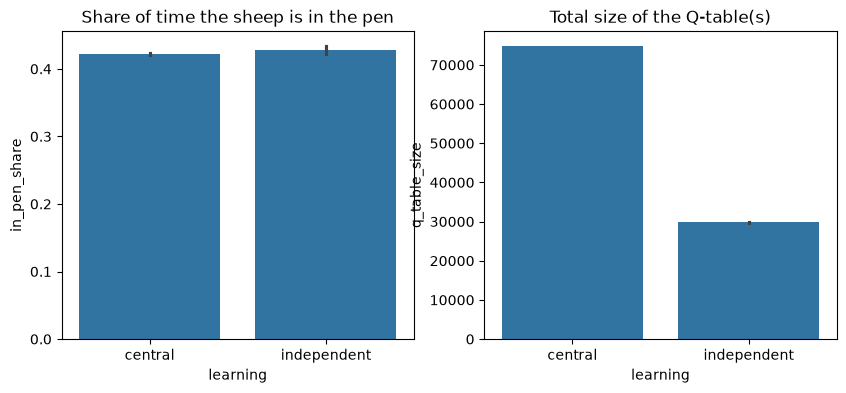

In [9]:
params = {"learning": ["central", "independent"]}

results = mesa.batch_run(
    HerdingModel,
    parameters=params,
    iterations=2,               # two runs per set-up
    max_steps=1_500_000,
    number_processes=1,
    data_collection_period=-1,  # only collect at the end of the run
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./herding_central_vs_independent.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(results, x="learning", y="in_pen_share", ax=axes[0])
sns.barplot(results, x="learning", y="q_table_size", ax=axes[1])
axes[0].set_title("Share of time the sheep is in the pen")
axes[1].set_title("Total size of the Q-table(s)")
plt.show()

# Experiments for you
1. **Table size.** Look at the Q-table sizes. What would happen to the central learner with 3 dogs? And with 10? What about independent learners?
2. **Train longer.** Central learning can, in principle, learn the best possible joint behaviour, and independent learners can get stuck. Train both for 5 million steps (or more). Does central learning catch up, or even overtake?
3. **Exploring together.** With $\epsilon = 0.1$ the central learner picks a random *joint* action 10% of the time. Two independent learners each explore 10% of the time, on their own. How often does at least one of the two independent dogs do something random?
4. **Panicky sheep.** Set `sheep_panic=0.6`. Is the difference between central and independent learning smaller or bigger? Why?
5. **Seeing your partner.** Change `observe()` so that each independent learner only sees the sheep and *itself* (not the other dog). Is that better or worse? Think about two things: less information, but also a smaller table.
6. **Non-stationarity.** Train independent learners, then switch off learning for dog 1 (`learning = False`) and give dog 2 a fresh learner (empty Q-table). Does dog 2 learn faster with a partner that does not change anymore?